In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
from statsmodels.tsa.seasonal import seasonal_decompose

In [7]:
data= {
    "Month": pd.date_range(start="2020-01", periods=36, freq="ME"),
    "Sales":[
        120,130,150,160,170,190,210,200,195,180,175,160,
        130,140,155,165,175,195,220,210,200,185,180,165,
        140,150,165,175,185,205,230,220,210,195,190,175
    ],
}

In [9]:
df = pd.DataFrame(data)
df.head()

,Month,Sales
0,2020-01-31,120
1,2020-02-29,130
2,2020-03-31,150
3,2020-04-30,160
4,2020-05-31,170


In [10]:
df.set_index('Month',inplace=True)

In [11]:
df.head()

,Sales
Month,
2020-01-31,120
2020-02-29,130
2020-03-31,150
2020-04-30,160
2020-05-31,170


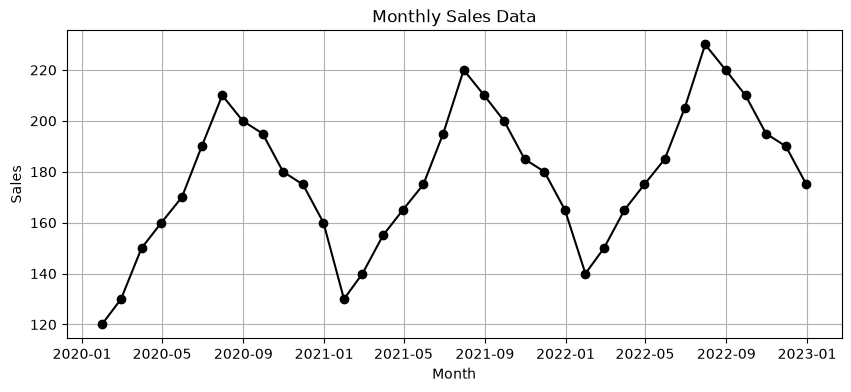

In [13]:
plt.figure(figsize=(10,4))
plt.plot(df, marker='o', linestyle='-', color='black')
plt.title('Monthly Sales Data')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.grid()
plt.show()

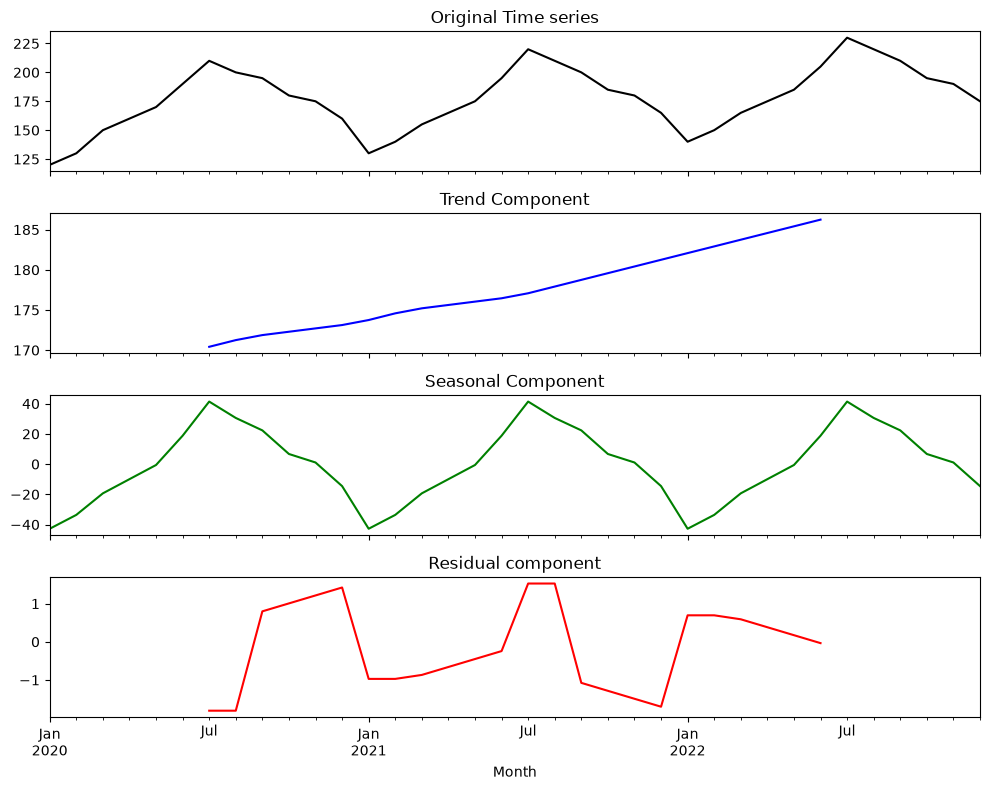

In [14]:
result= seasonal_decompose(df["Sales"],model="additive", period=12)

fig,axes= plt.subplots(4,1,figsize=(10,8),sharex=True)

result.observed.plot(ax=axes[0],title="Original Time series",color="black")
result.trend.plot(ax=axes[1],title="Trend Component",color="blue")
result.seasonal.plot(ax=axes[2],title="Seasonal Component",color="green")
result.resid.plot(ax=axes[3],title="Residual component",color="red")

plt.tight_layout()
plt.show()

# Stationary Series

In [15]:
from statsmodels.tsa.stattools import adfuller
import numpy as np

In [16]:
np.random.seed(42)
stationary_series = np.random.normal(0,1,100)

In [19]:
non_stationary_series = np.cumsum(np.random.normal(0,1,100))

In [21]:
p_val_stationary= adfuller(stationary_series)[1]
p_val_non_stationary= adfuller(non_stationary_series)[1]

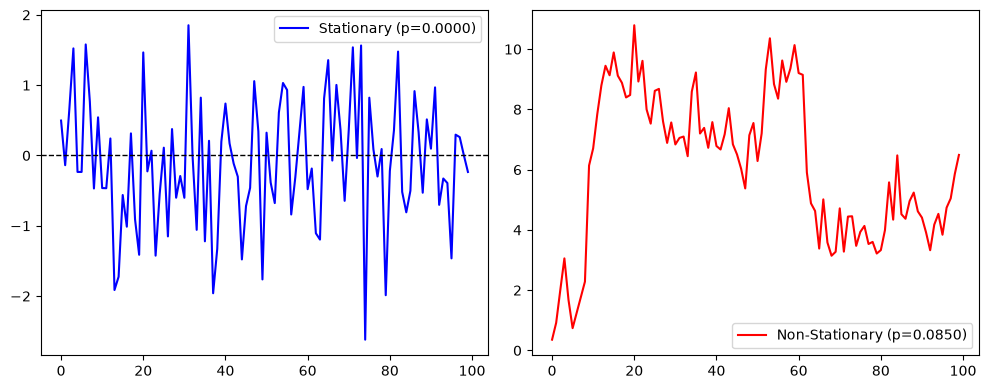

(np.float64(1.1655044784188833e-17), np.float64(0.08497656878623072))

In [22]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(stationary_series, label=f"Stationary (p={p_val_stationary:.4f})",color='blue')
plt.axhline(y=0,color='black',linestyle='--', linewidth=1)
plt.legend()

plt.subplot(1,2,2)
plt.plot(non_stationary_series, label=f"Non-Stationary (p={p_val_non_stationary:.4f})",color='red')
plt.legend()

plt.tight_layout()
plt.show()

p_val_stationary, p_val_non_stationary

In [23]:
from statsmodels.tsa.ar_model import AutoReg

In [24]:
data=[22,24,25,26,27,28] # Temperatures for day 7

In [29]:
model=AutoReg(data,lags=2) # AR(1)
model_fit= model.fit()

In [26]:
prediction= model_fit.predict(start=len(data),end=len(data))
print(prediction)


[28.59459459]


# MA Model

In [30]:
from statsmodels.tsa.arima.model import ARIMA

In [31]:
sales=[220,250,230,260,270,280,275]

In [32]:
model= ARIMA(sales, order=(0,0,1))
model_fit=model.fit()

In [33]:
prediction=model_fit.predict(start=len(sales),end=len(sales))
print(prediction)

[258.33045072]


# ARMA Model

In [34]:
temperature = [28,30,29,32,33,34,35]

In [35]:
model=ARIMA(temperature,order=(1,0,1))
model_fit=model.fit()

In [36]:
prediction=model_fit.predict(start=len(sales),end=len(sales))
print(prediction)

[34.38640463]
